# Contagem de veículos de dia e à noite

O script processa o vídeo. Este notebook lê os CSVs e confere os resultados. Execute-o na raiz do projeto após rodar `contar_veiculos.py`.

In [1]:
import csv
from collections import Counter
from pathlib import Path

pasta = Path("resultados")

def ler_csv(nome):
    with (pasta / nome).open(encoding="utf-8", newline="") as arquivo:
        return list(csv.DictReader(arquivo))

passagens = ler_csv("passagens.csv")
referencia = ler_csv("referencia_yolov5m.csv")
totais = Counter(linha["periodo"] for linha in passagens)
tipos = Counter(linha["tipo"] for linha in passagens if linha["periodo"] == "dia")
registrados = {linha["periodo"]: int(linha["veiculos"]) for linha in ler_csv("contagem.csv")}
assert registrados == {"dia": totais["dia"], "noite": totais["noite"], "total": len(passagens)}
print("Dia:", totais["dia"], "| Noite:", totais["noite"], "| Total:", len(passagens))
print("Classificação automática de dia:", dict(sorted(tipos.items())))


Dia: 15 | Noite: 6 | Total: 21
Classificação automática de dia: {'caminhao': 2, 'carro': 12, 'onibus': 1}


## Comparação por passagem

A referência é a execução anterior com YOLOv5m, no mesmo vídeo. Os registros são pareados pela ordem dentro de cada período e sentido. Uma diferença de até três quadros (0,25 s a 12 quadros/s) fica dentro da tolerância adotada. A comparação mede concordância entre execuções.

In [2]:
comparacao = []
for periodo in ("dia", "noite"):
    for sentido in ("aproximacao", "afastamento"):
        atual = [e for e in passagens if (e["periodo"], e["sentido"]) == (periodo, sentido)]
        base = [e for e in referencia if (e["periodo"], e["sentido"]) == (periodo, sentido)]
        for anterior, evento in zip(base, atual):
            diferenca = int(evento["quadro"]) - int(anterior["quadro"])
            comparacao.append({
                "periodo": periodo,
                "sentido": sentido,
                "quadro_referencia": int(anterior["quadro"]),
                "quadro_atual": int(evento["quadro"]),
                "diferenca_quadros": diferenca,
                "dentro_da_tolerancia": abs(diferenca) <= 3,
            })

metricas = []
for periodo in ("dia", "noite", "total"):
    selecionados = [e for e in comparacao if periodo == "total" or e["periodo"] == periodo]
    n_base = sum(periodo == "total" or e["periodo"] == periodo for e in referencia)
    n_atual = len(passagens) if periodo == "total" else totais[periodo]
    metricas.append({
        "periodo": periodo,
        "contagem_referencia": n_base,
        "contagem_atual": n_atual,
        "erro_absoluto": abs(n_atual - n_base),
        "pares_ate_3_quadros": sum(e["dentro_da_tolerancia"] for e in selecionados),
        "maior_diferenca_quadros": max((abs(e["diferenca_quadros"]) for e in selecionados), default=0),
    })

for linha in metricas:
    print(linha)


{'periodo': 'dia', 'contagem_referencia': 15, 'contagem_atual': 15, 'erro_absoluto': 0, 'pares_ate_3_quadros': 15, 'maior_diferenca_quadros': 3}
{'periodo': 'noite', 'contagem_referencia': 6, 'contagem_atual': 6, 'erro_absoluto': 0, 'pares_ate_3_quadros': 6, 'maior_diferenca_quadros': 0}
{'periodo': 'total', 'contagem_referencia': 21, 'contagem_atual': 21, 'erro_absoluto': 0, 'pares_ate_3_quadros': 21, 'maior_diferenca_quadros': 3}


## Evidências visuais

O gráfico mostra contagens e momentos de passagem. A última imagem amplia o quadro 77, onde o YOLOv5n rotula um caminhão vermelho como ônibus.

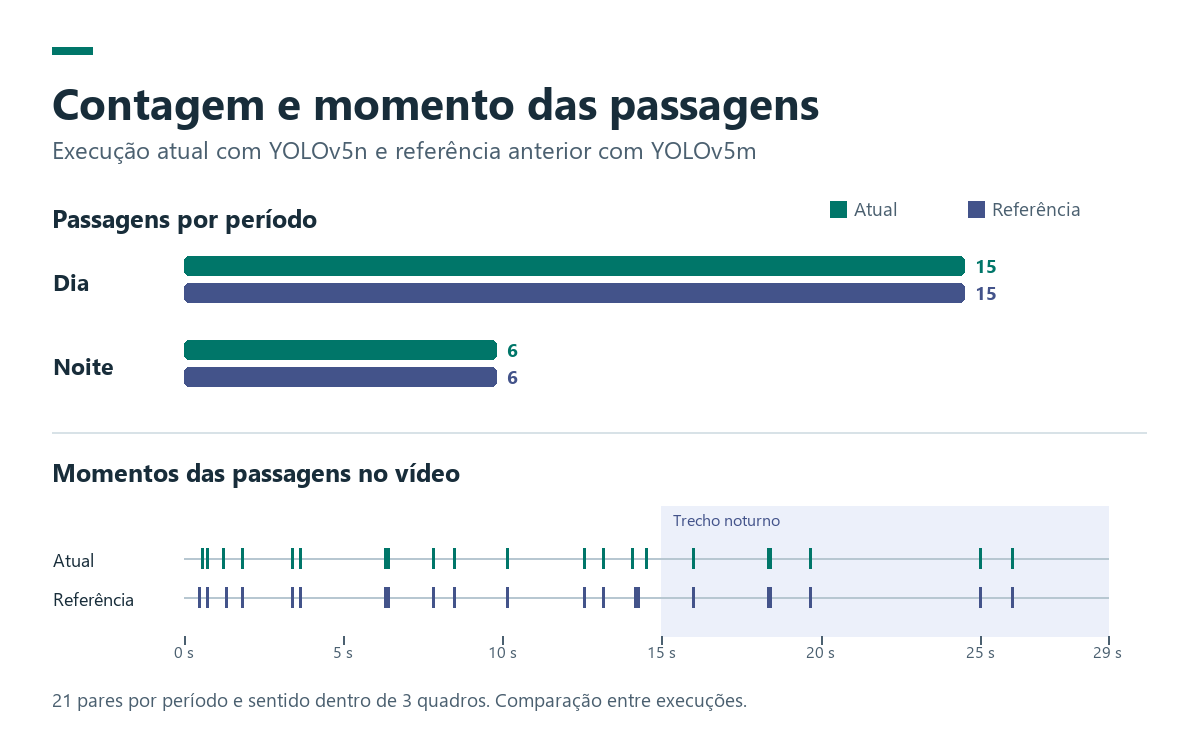

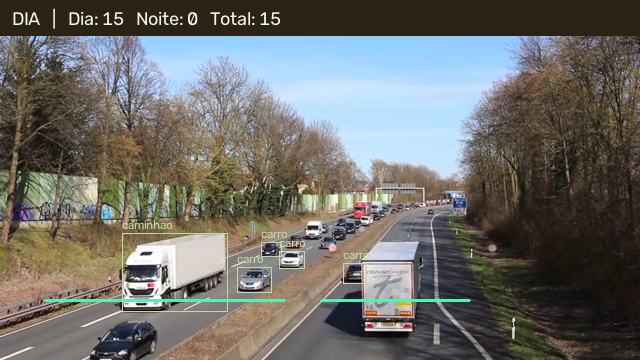

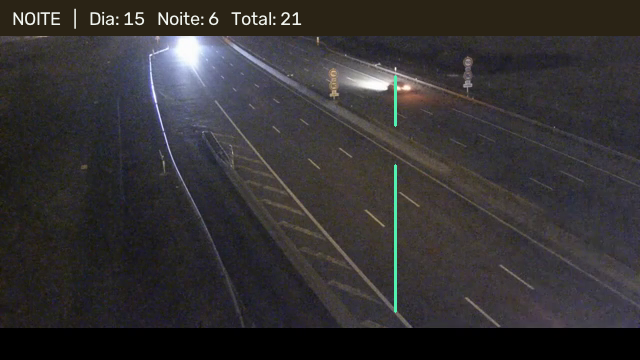

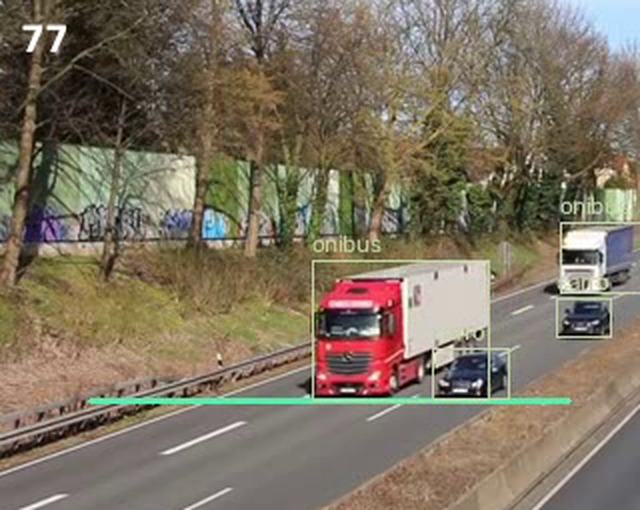

In [3]:
from IPython.display import Image, display

for nome in ("grafico_contagens.png", "contagem_dia.png", "contagem_noite.png", "evidencia_classificacao.png"):
    display(Image(filename=str(pasta / nome)))
